# ACDC membership data: exploratory analysis for review

**Purpose.** Build evidence for customer segmentation under CRISP-DM. This is an EDA draft for group review, not a clustering solution or final submission. The unit of analysis is a member record. The source is `data/acdc_dataset.csv`; the assignment brief is `../DM2627_ProjectGuidelines.pdf`.

**Questions.** What varies across members? Which attributes might distinguish value and behavior? Which data issues could distort clustering? What should be investigated before modeling?

**How to read this notebook.** Raw values remain in `raw`. A separate `df` removes only exact duplicate rows. Variables in `view` are provisional analysis views; they do not overwrite the source. Plots summarize patterns and do not establish causation.

## 1. Setup and data grain

Run all cells from the top. The path works whether Jupyter starts in the repository root or the `notebooks` directory.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", palette="colorblind")
pd.set_option("display.max_columns", 40)

possible_paths = [Path("data/acdc_dataset.csv"), Path("../data/acdc_dataset.csv")]
data_path = next((path for path in possible_paths if path.exists()), None)
if data_path is None:
    raise FileNotFoundError("Could not find data/acdc_dataset.csv")
raw = pd.read_csv(data_path, sep=";")
df = raw.drop_duplicates().reset_index(drop=True)
print(f"Raw: {raw.shape[0]:,} rows, {raw.shape[1]} columns")
print(f"Exact duplicate rows removed: {len(raw) - len(df):,}")
print(f"Repeated member IDs after deduplication: {df['member_id'].duplicated().sum():,}")
display(df.head(3))

Raw: 15,465 rows, 31 columns
Exact duplicate rows removed: 15
Repeated member IDs after deduplication: 0


,member_id,age,gender,industry,country,is_team_account,n_colleagues_on_account,plan_tier,plan_days_per_week,membership_start,membership_end,last_badge_swipe,days_since_last_visit,total_visits,avg_weekly_visits,entitled_visits_last_period,actual_visits_last_period,meeting_room_hours,event_space_hours,guest_passes_issued,uses_meeting_rooms,uses_event_space,uses_guest_passes,uses_print,uses_mail_handling,uses_phone_booths,uses_day_passes,uses_storage,uses_bike_locker,n_renewals,lifetime_value
0,CW000001,38.0,Female,Information Technology,Portugal,False,0,flex,3,2021-08-01,2023-03-06,2023-03-23,-17,220,2.65,26.09,22,0.0,0.0,18.0,False,False,True,0,False,True,True,False,False,2,4477.97
1,CW000002,38.0,Male,Information Technology,Portugal,True,2,HOT_DESK,2,2023-11-24,1970-01-01,2023-11-24,37,2,0.32,10.68,1,0.0,0.0,0.0,False,False,False,0,True,False,False,False,False,0,165.86
2,CW000003,43.0,Male,Education,DE,True,1,flex,3,2021-12-03,1970-01-01,2023-07-22,163,19,0.17,26.09,2,0.0,0.0,0.0,False,False,False,0,False,False,False,False,False,1,4486.17


The row represents a member, not a transaction. `member_id` is an identifier and must not be a clustering input. Monetary and visit totals are accumulated over different membership histories, so comparisons need care.

In [2]:
schema = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "non_missing": df.notna().sum(),
    "missing": df.isna().sum(),
    "distinct_non_missing": df.nunique(dropna=True),
})
display(schema)

,dtype,non_missing,missing,distinct_non_missing
member_id,str,15450,0,15450
age,float64,14893,557,84
gender,str,14920,530,12
industry,str,15450,0,43
country,str,15021,429,33
is_team_account,bool,15450,0,2
n_colleagues_on_account,int64,15450,0,11
plan_tier,str,15345,105,19
plan_days_per_week,int64,15450,0,6
membership_start,str,15450,0,1539


## 2. Missing values and their possible meaning

There is **no percentage cutoff** that identifies MCAR, MAR, or MNAR. MCAR means the probability of missingness does not depend on observed or unseen values. MAR means it may depend on observed variables after conditioning on them. MNAR means it still depends on the unseen value. Group-rate differences can challenge MCAR, but observed data alone cannot prove MAR or rule out MNAR. A blank may also be structural or caused by the recording process.

,missing_rows,missing_pct
meeting_room_hours,1295,8.38
guest_passes_issued,1269,8.21
lifetime_value,1040,6.73
age,557,3.61
gender,530,3.43
country,429,2.78
plan_tier,105,0.68


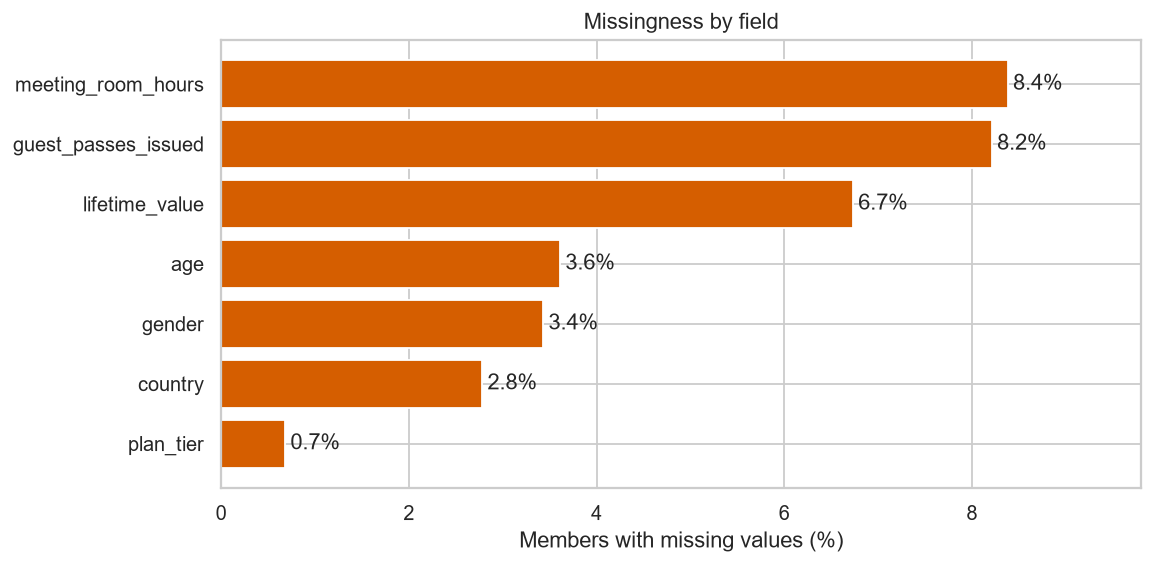

In [3]:
missing = df.isna().sum().to_frame("missing_rows")
missing["missing_pct"] = (100 * missing["missing_rows"] / len(df)).round(2)
missing = missing.loc[missing["missing_rows"] > 0].sort_values("missing_pct")
display(missing.sort_values("missing_pct", ascending=False))

fig, ax = plt.subplots(figsize=(9, 4.5))
bars = ax.barh(missing.index, missing["missing_pct"], color="#D55E00")
ax.bar_label(bars, fmt="%.1f%%", padding=3)
ax.set(xlabel="Members with missing values (%)", title="Missingness by field")
ax.set_xlim(0, missing["missing_pct"].max() * 1.17)
fig.tight_layout()
plt.show()

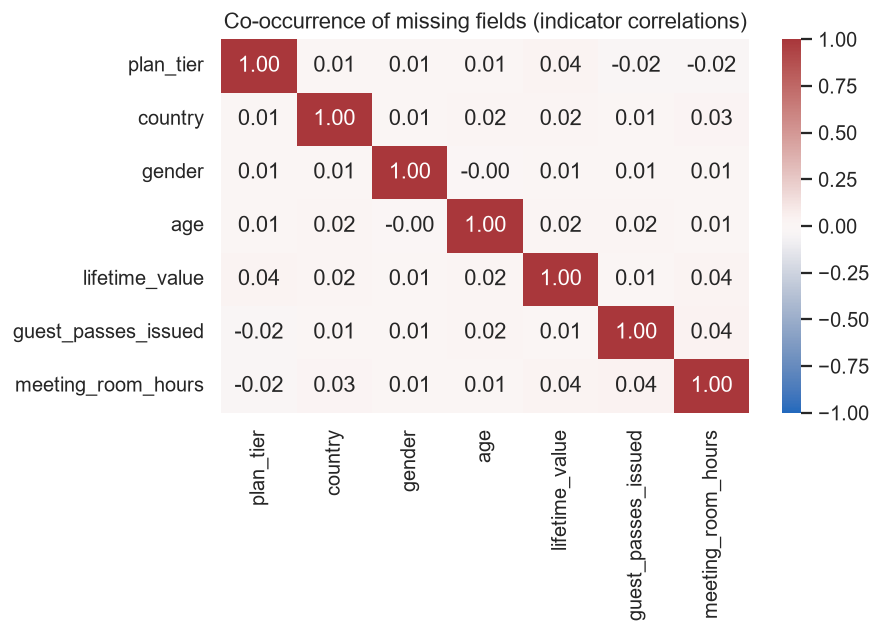

In [4]:
missing_flags = df[missing.index].isna().astype(int)
fig, ax = plt.subplots(figsize=(7, 5))
sns.heatmap(missing_flags.corr(), vmin=-1, vmax=1, center=0,
            cmap="vlag", annot=True, fmt=".2f", ax=ax)
ax.set_title("Co-occurrence of missing fields (indicator correlations)")
fig.tight_layout()
plt.show()

The second heatmap compares **missingness indicators**, not the values themselves. Near-zero cells show little pairwise co-occurrence; they do not prove MCAR. For meeting-room hours and guest passes, the related usage flag is a plausible recording-process clue. Compare missing rates by flag and plan tier, then ask how the data was collected before choosing an imputation rule.

In [5]:
def missing_rate_by(group, target):
    table = (pd.DataFrame({"group": group, "missing": df[target].isna()})
             .groupby("group", dropna=False)["missing"]
             .agg(members="size", missing_rows="sum", missing_rate="mean"))
    table["missing_pct"] = (table.pop("missing_rate") * 100).round(1)
    return table

tier_key = (df["plan_tier"].astype("string").str.strip().str.lower()
            .str.replace(r"[\s_]+", "", regex=True))
tier_map = {"hotdesk": "Hot desk", "flex": "Flex",
            "dedicateddesk": "Dedicated desk", "fulltime": "Full time",
            "privateoffice": "Private office"}
tier = tier_key.map(tier_map)
print("Meeting-room hours by usage flag")
display(missing_rate_by(df["uses_meeting_rooms"], "meeting_room_hours"))
print("Meeting-room hours by plan tier")
display(missing_rate_by(tier.fillna("Missing tier"), "meeting_room_hours"))
print("Guest passes by usage flag")
display(missing_rate_by(df["uses_guest_passes"], "guest_passes_issued"))

Meeting-room hours by usage flag
Meeting-room hours by plan tier
Guest passes by usage flag


,members,missing_rows,missing_pct
group,,,
False,10192,902,8.9
True,5258,393,7.5


,members,missing_rows,missing_pct
group,,,
Dedicated desk,1549,59,3.8
Flex,5449,473,8.7
Full time,2471,140,5.7
Hot desk,5212,611,11.7
Missing tier,105,1,1.0
Private office,664,11,1.7


,members,missing_rows,missing_pct
group,,,
False,12639,1066,8.4
True,2811,203,7.2


**Interpretation boundary.** Different observed-group rates make MCAR less plausible for that field. They do not establish why a value is missing. No value is filled or dropped here. Tomorrow's review should identify which missing fields are business-critical and what source documentation would resolve their meaning.

## 3. Categories, parsing, and consistency

Some apparent categories are spelling variants. The normalized labels below are for exploration only. Confirm the mapping with ACDC before using it for clustering, particularly for country aliases and free-text industry values.

Examples of country labels needing review:


,raw_distinct,provisional_distinct
gender,12,3.0
plan_tier,19,5.0
country,33,NaN
industry,43,NaN


,members
country,
Portugal,9950
United Kingdom,1104
Germany,850
Spain,711
France,506
Netherlands,463
Other (Europe),429
NaN,429
Ireland,232


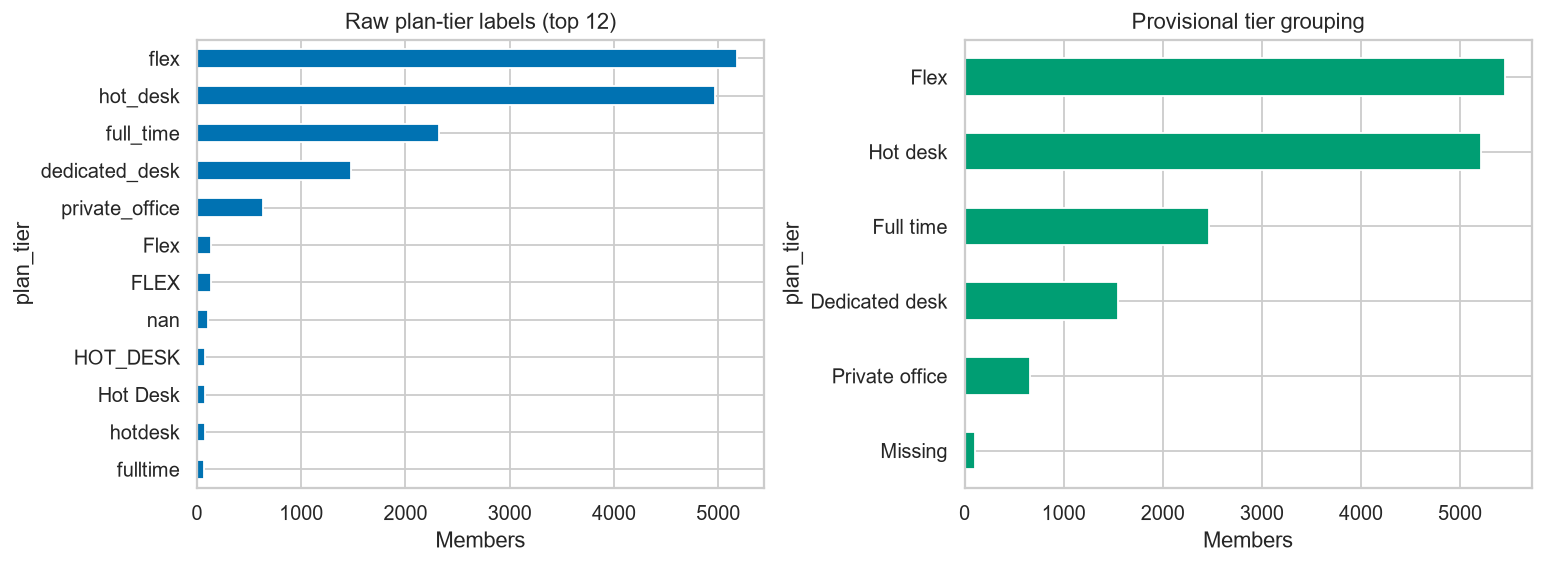

In [6]:
gender_key = df["gender"].astype("string").str.strip().str.lower()
gender = gender_key.map({"f": "Female", "female": "Female",
                         "m": "Male", "male": "Male",
                         "o": "Other", "other": "Other"})
category_audit = pd.DataFrame({
    "raw_distinct": [df["gender"].nunique(), df["plan_tier"].nunique(),
                     df["country"].nunique(), df["industry"].nunique()],
    "provisional_distinct": [gender.nunique(), tier.nunique(), np.nan, np.nan],
}, index=["gender", "plan_tier", "country", "industry"])
display(category_audit)
print("Examples of country labels needing review:")
display(df["country"].value_counts(dropna=False).head(18).to_frame("members"))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
df["plan_tier"].value_counts(dropna=False).head(12).sort_values().plot.barh(
    ax=axes[0], color="#0072B2", title="Raw plan-tier labels (top 12)")
tier.fillna("Missing").value_counts().sort_values().plot.barh(
    ax=axes[1], color="#009E73", title="Provisional tier grouping")
for ax in axes: ax.set_xlabel("Members")
fig.tight_layout()
plt.show()

In [7]:
value_text = df["lifetime_value"].astype("string")
value_direct = pd.to_numeric(value_text, errors="coerce")
value_parsed = pd.to_numeric(
    value_text.str.replace(",", "", regex=False)
              .str.replace("€", "", regex=False).str.strip(), errors="coerce")
parse_audit = pd.Series({
    "Originally missing": int(value_text.isna().sum()),
    "Present but not directly numeric": int((value_text.notna() & value_direct.isna()).sum()),
    "Still unparsed after format-only conversion": int((value_text.notna() & value_parsed.isna()).sum()),
    "Negative after conversion": int((value_parsed < 0).sum()),
    "Euro-symbol entries": int(value_text.fillna("").str.contains("€", regex=False).sum()),
    "Comma-formatted entries": int(value_text.fillna("").str.contains(",", regex=False).sum()),
}, name="rows")
display(parse_audit.to_frame())
display(value_text[value_text.notna() & value_direct.isna()].drop_duplicates().head(8).to_frame("raw_example"))

,rows
Originally missing,1040
Present but not directly numeric,401
Still unparsed after format-only conversion,0
Negative after conversion,82
Euro-symbol entries,291
Comma-formatted entries,110


,raw_example
70,246.10 €
83,446.70 €
139,"4,311.15"
211,859.65 €
220,843.67 €
240,646.66 €
323,485.65 €
359,0.00 €


For plots only, the comma and euro symbol are treated as formatting. The source strings remain intact. Negative monetary values are excluded from nonnegative-value plots and flagged for follow-up; this is not an imputation or a final cleaning rule.

,rows
Start dates in day/month/year format,637
End dates in day/month/year format,461
Swipe dates in day/month/year format,637
Unparsed start/end/swipe dates,0
End date equals 1970-01-01,3954
Other end dates before start,152
Last swipe before start,94
Last swipe after non-placeholder end,213
Days since last visit equals 999,1298
Negative days since last visit,56


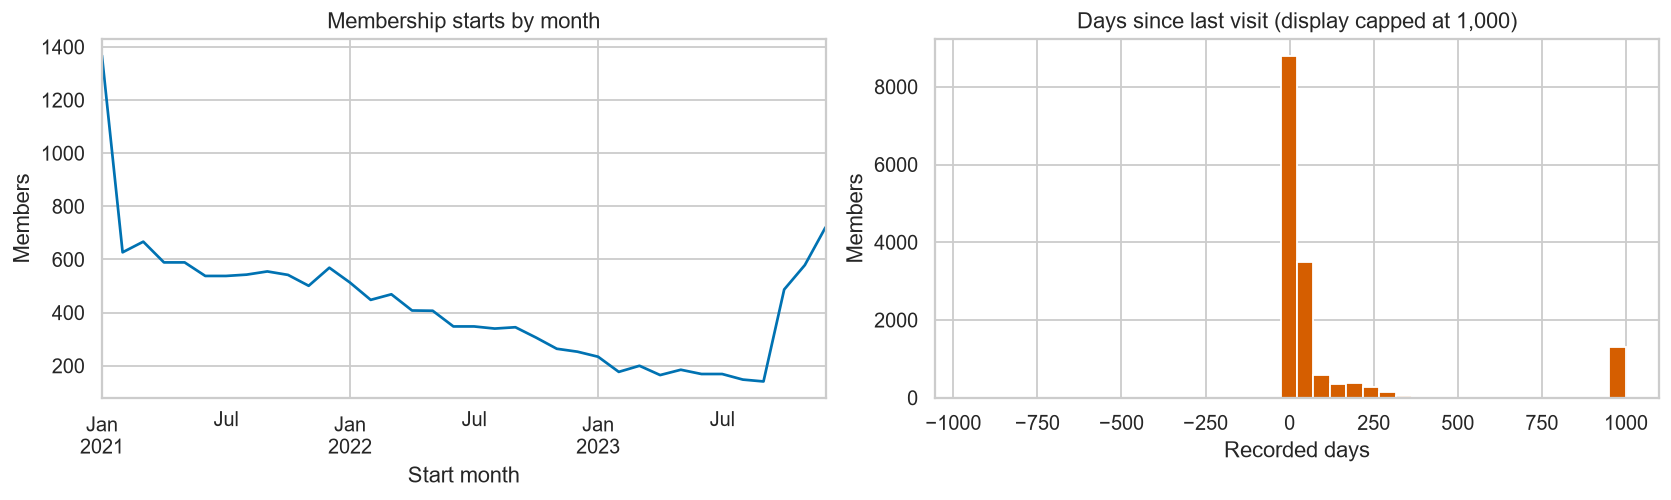

In [8]:
def parse_mixed_dates(values):
    # Read ISO and day/month/year dates without guessing ambiguous days.
    text = values.astype("string")
    iso = pd.to_datetime(text.where(text.str.contains("-", regex=False)),
                         format="%Y-%m-%d", errors="coerce")
    dmy = pd.to_datetime(text.where(text.str.contains("/", regex=False)),
                         format="%d/%m/%Y", errors="coerce")
    return iso.fillna(dmy)

start = parse_mixed_dates(df["membership_start"])
end = parse_mixed_dates(df["membership_end"])
swipe = parse_mixed_dates(df["last_badge_swipe"])
end_placeholder = end.eq(pd.Timestamp("1970-01-01"))
date_audit = pd.Series({
    "Start dates in day/month/year format": int(df["membership_start"].str.contains("/", regex=False).sum()),
    "End dates in day/month/year format": int(df["membership_end"].str.contains("/", regex=False).sum()),
    "Swipe dates in day/month/year format": int(df["last_badge_swipe"].str.contains("/", regex=False).sum()),
    "Unparsed start/end/swipe dates": int(start.isna().sum() + end.isna().sum() + swipe.isna().sum()),
    "End date equals 1970-01-01": int(end_placeholder.sum()),
    "Other end dates before start": int(((end < start) & ~end_placeholder).sum()),
    "Last swipe before start": int((swipe < start).sum()),
    "Last swipe after non-placeholder end": int(((swipe > end) & ~end_placeholder).sum()),
    "Days since last visit equals 999": int(df["days_since_last_visit"].eq(999).sum()),
    "Negative days since last visit": int(df["days_since_last_visit"].lt(0).sum()),
}, name="rows")
display(date_audit.to_frame())

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
start.dt.to_period("M").value_counts().sort_index().plot.line(
    ax=axes[0], color="#0072B2", title="Membership starts by month")
axes[0].set(xlabel="Start month", ylabel="Members")
df["days_since_last_visit"].clip(upper=1000).hist(
    bins=40, ax=axes[1], color="#D55E00")
axes[1].set(title="Days since last visit (display capped at 1,000)",
            xlabel="Recorded days", ylabel="Members")
fig.tight_layout()
plt.show()

The mixed date formats parse when each format is specified. A 1970 end date and a large spike at 999 days are **possible placeholders**, not confirmed facts. The reference date for `days_since_last_visit` is unclear; do not use it as a precise recency measure until ACDC defines it. Date order violations need record-level review before tenure or churn features are built.

,rows
Age outside 18–100 (screening rule),143
Negative total visits,42
Negative meeting-room hours,16
Negative event-space hours,8
Negative guest passes,7
Negative renewals,66
Positive meeting hours but flag false,55
Actual visits exceed entitlement,8
Team flag and colleague count disagree,0


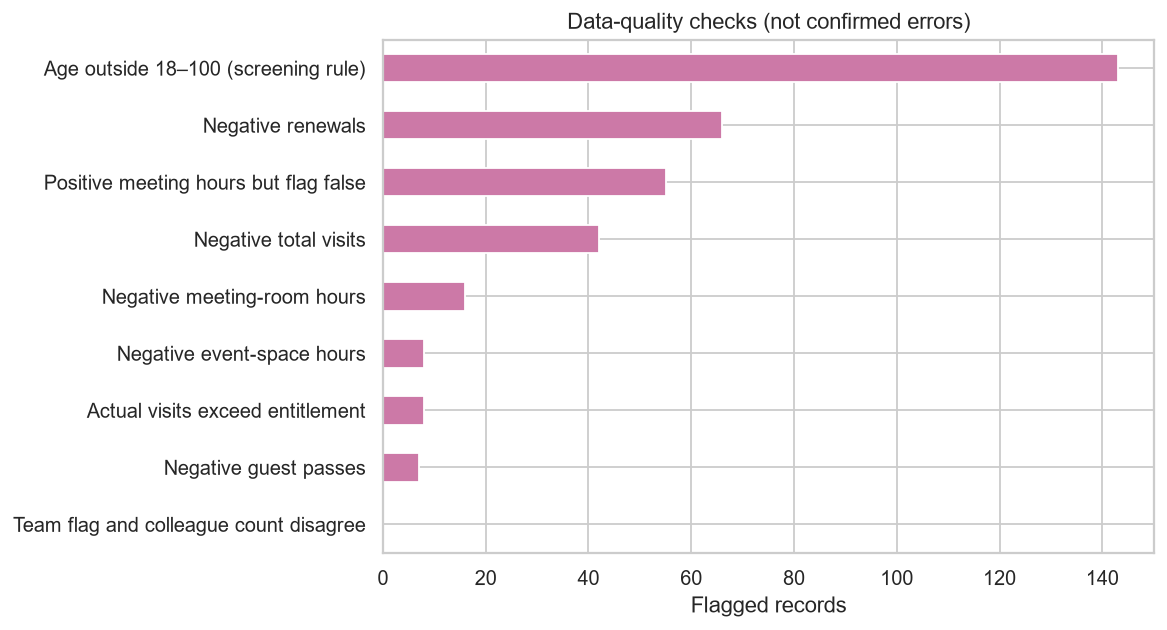

In [9]:
checks = pd.Series({
    "Age outside 18–100 (screening rule)": int((df["age"].notna() & ~df["age"].between(18, 100)).sum()),
    "Negative total visits": int(df["total_visits"].lt(0).sum()),
    "Negative meeting-room hours": int(df["meeting_room_hours"].lt(0).sum()),
    "Negative event-space hours": int(df["event_space_hours"].lt(0).sum()),
    "Negative guest passes": int(df["guest_passes_issued"].lt(0).sum()),
    "Negative renewals": int(df["n_renewals"].lt(0).sum()),
    "Positive meeting hours but flag false": int((~df["uses_meeting_rooms"] & df["meeting_room_hours"].gt(0)).sum()),
    "Actual visits exceed entitlement": int((df["actual_visits_last_period"] > df["entitled_visits_last_period"]).sum()),
    "Team flag and colleague count disagree": int(((~df["is_team_account"] & df["n_colleagues_on_account"].gt(0)) | (df["is_team_account"] & df["n_colleagues_on_account"].eq(0))).sum()),
}, name="rows")
display(checks.to_frame())
fig, ax = plt.subplots(figsize=(9, 5))
checks.sort_values().plot.barh(ax=ax, color="#CC79A7")
ax.set(xlabel="Flagged records", title="Data-quality checks (not confirmed errors)")
fig.tight_layout()
plt.show()

These are **review flags**, not automatic deletions. For example, visits above entitlement may reflect extra paid visits; negative hours may be reversals or input errors. The data dictionary does not resolve those cases. Preserve the raw values and ask for source-system rules.

## 4. Member distributions and value

Histograms show shape, tails, and possible groups. Log transforms are used only for display when a variable is highly skewed. Zeros stay visible; invalid negative values are set aside in the plotted view and counted above.

In [10]:
view = pd.DataFrame(index=df.index)
view["tier"] = tier
view["age"] = df["age"].where(df["age"].between(18, 100))
view["total_visits"] = df["total_visits"].where(df["total_visits"] >= 0)
view["weekly_visits"] = df["avg_weekly_visits"]
view["meeting_hours"] = df["meeting_room_hours"].where(df["meeting_room_hours"] >= 0)
view["event_hours"] = df["event_space_hours"].where(df["event_space_hours"] >= 0)
view["guest_passes"] = df["guest_passes_issued"].where(df["guest_passes_issued"] >= 0)
view["renewals"] = df["n_renewals"].where(df["n_renewals"] >= 0)
view["lifetime_value"] = value_parsed.where(value_parsed >= 0)
view["plan_days"] = df["plan_days_per_week"]
view["entitled_visits"] = df["entitled_visits_last_period"]
view["actual_visits"] = df["actual_visits_last_period"]
view["colleagues"] = df["n_colleagues_on_account"]
display(view.describe(percentiles=[.25, .5, .75, .95, .99]).T.round(2))

,count,mean,std,min,25%,50%,75%,95%,99%,max
age,14750.0,34.747119,8.393109,18.0,29.0,34.0,40.0,49.0,55.0,93.0
total_visits,15408.0,110.780893,183.027859,0.0,8.0,35.0,132.0,523.0,693.93,6530.0
weekly_visits,15450.0,1.77717,1.937986,0.0,0.71,1.42,2.41,4.39,5.32,47.4
meeting_hours,14139.0,33.143978,428.58852,0.0,0.0,0.0,7.2,145.51,326.8,41220.0
event_hours,15442.0,5.12185,26.025192,0.0,0.0,0.0,0.0,29.5,127.439,602.8
guest_passes,14174.0,6.167278,23.440798,0.0,0.0,0.0,0.0,42.0,117.27,589.0
renewals,15384.0,1.019436,1.339502,0.0,0.0,0.0,2.0,4.0,5.0,6.0
lifetime_value,14328.0,6447.522337,62965.321045,0.0,256.7175,859.225,5100.6625,15410.644,25680.2335,3371260.0
plan_days,15450.0,3.386667,1.458691,0.0,2.0,3.0,5.0,5.0,7.0,9.0
entitled_visits,15450.0,27.512777,13.478105,0.0,17.39,26.09,43.48,43.48,60.87,78.27


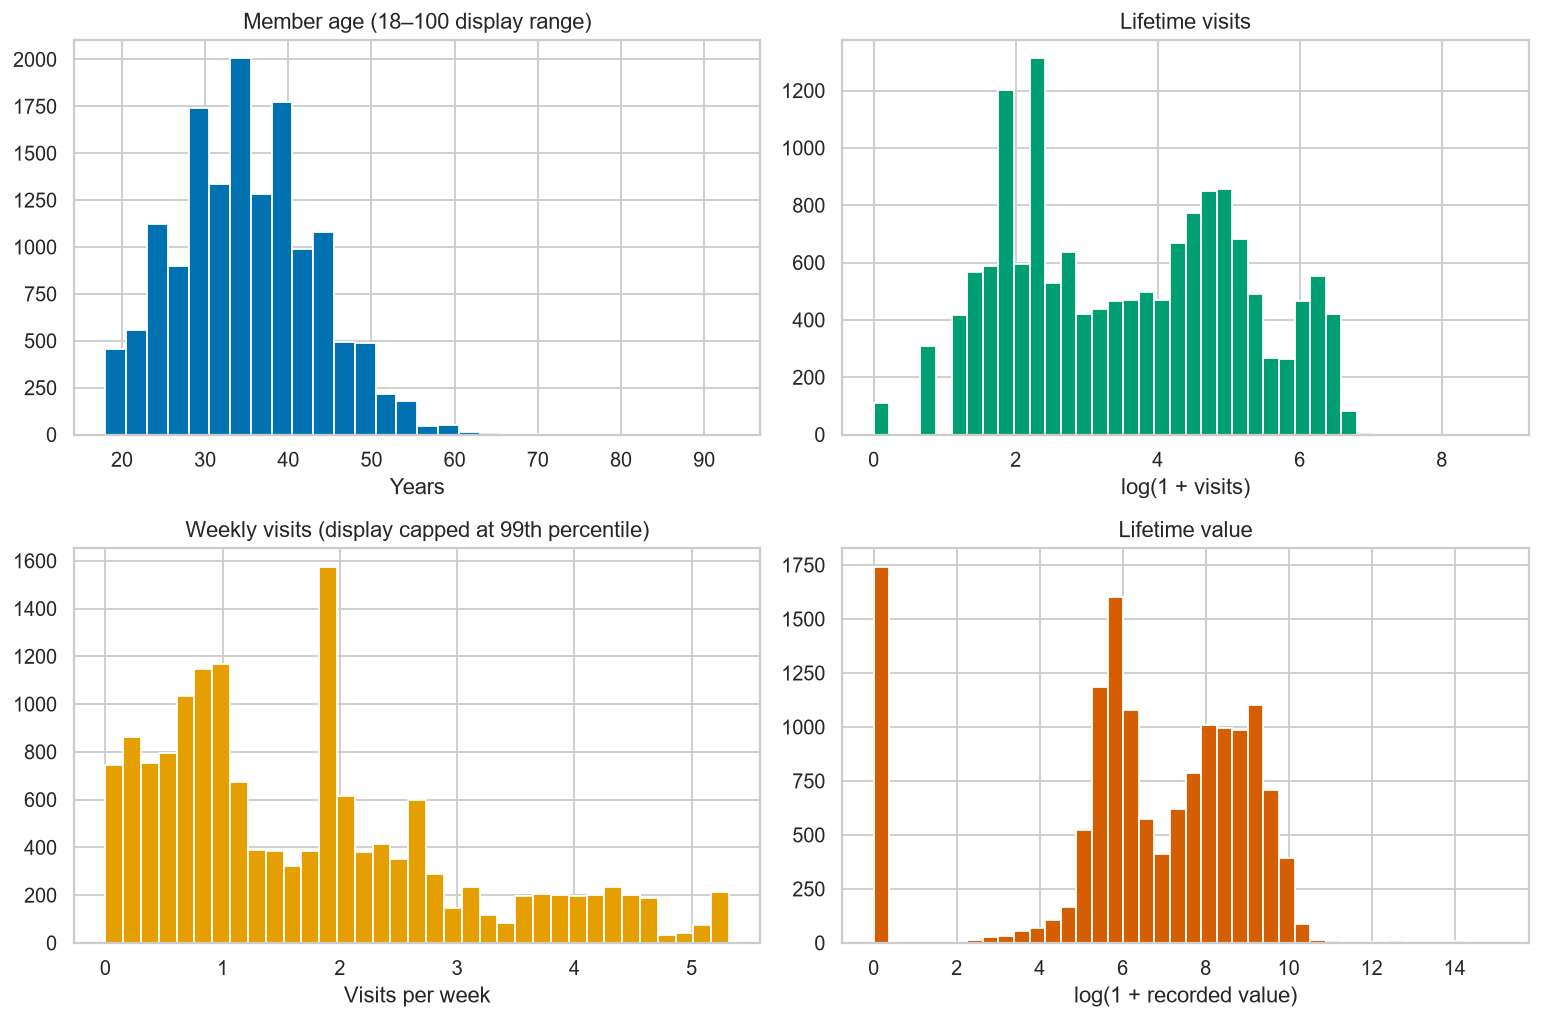

In [11]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
view["age"].hist(bins=30, ax=axes[0, 0], color="#0072B2")
axes[0, 0].set(title="Member age (18–100 display range)", xlabel="Years")
np.log1p(view["total_visits"]).hist(bins=40, ax=axes[0, 1], color="#009E73")
axes[0, 1].set(title="Lifetime visits", xlabel="log(1 + visits)")
view["weekly_visits"].clip(upper=view["weekly_visits"].quantile(.99)).hist(
    bins=35, ax=axes[1, 0], color="#E69F00")
axes[1, 0].set(title="Weekly visits (display capped at 99th percentile)", xlabel="Visits per week")
np.log1p(view["lifetime_value"]).hist(bins=40, ax=axes[1, 1], color="#D55E00")
axes[1, 1].set(title="Lifetime value", xlabel="log(1 + recorded value)")
fig.tight_layout()
plt.show()

In [12]:
positive_value = view["lifetime_value"].dropna()
value_summary = pd.Series({
    "Members with nonnegative parsed value": len(positive_value),
    "Median": positive_value.median(),
    "Mean": positive_value.mean(),
    "99th percentile": positive_value.quantile(.99),
    "Maximum": positive_value.max(),
    "Share of total value held by top 1%": 100 * positive_value.nlargest(max(1, round(len(positive_value) * .01))).sum() / positive_value.sum(),
}, name="value")
display(value_summary.to_frame().round(2))

,value
Members with nonnegative parsed value,14328.00
Median,859.22
Mean,6447.52
99th percentile,25680.23
Maximum,3371260.00
Share of total value held by top 1%,46.31


The value distribution is extremely skewed: a small number of records can dominate means and distance-based clustering. Medians, ranks, log scaling, and explicit outlier review are more informative here than raw means alone. Lifetime value also accumulates with membership length, so it is not a pure measure of current engagement.

## 5. Differences across plans and behavior

These are **descriptive comparisons**, not segment assignments. Plan tier is an existing business category, so later clustering should test whether behavior reveals additional structure beyond it.

,members,median_lifetime_value,median_weekly_visits,median_total_visits
tier,,,,
Hot desk,5212,320.9,1.0,10.0
Flex,5449,1200.8,1.9,44.5
Dedicated desk,1549,10378.7,3.9,396.0
Full time,2471,4660.7,1.6,39.0
Private office,664,20000.1,1.0,131.0


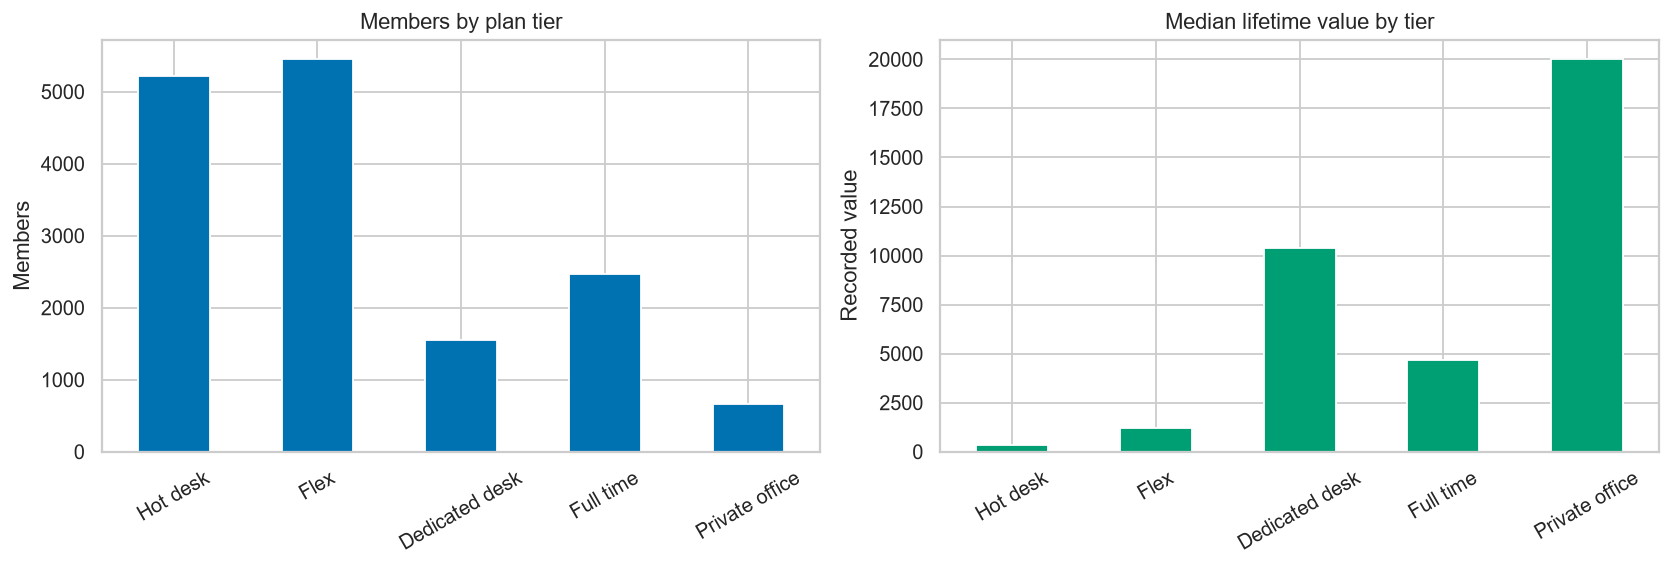

In [13]:
tier_order = ["Hot desk", "Flex", "Dedicated desk", "Full time", "Private office"]
tier_profile = (view.groupby("tier")
                .agg(members=("age", "size"),
                     median_lifetime_value=("lifetime_value", "median"),
                     median_weekly_visits=("weekly_visits", "median"),
                     median_total_visits=("total_visits", "median"))
                .reindex(tier_order))
display(tier_profile.round(1))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
tier_profile["members"].plot.bar(ax=axes[0], color="#0072B2")
axes[0].set(title="Members by plan tier", xlabel="", ylabel="Members")
tier_profile["median_lifetime_value"].plot.bar(ax=axes[1], color="#009E73")
axes[1].set(title="Median lifetime value by tier", xlabel="", ylabel="Recorded value")
for ax in axes: ax.tick_params(axis="x", rotation=30)
fig.tight_layout()
plt.show()

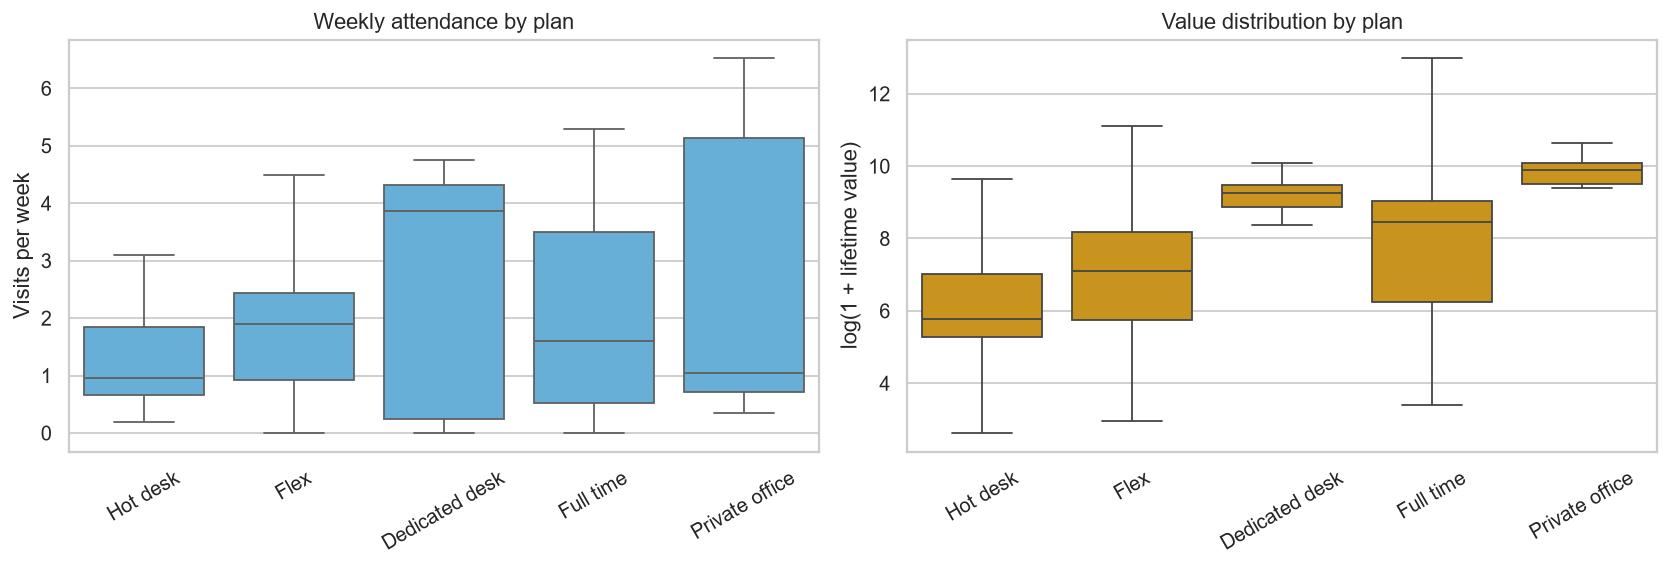

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.boxplot(data=view, x="tier", y="weekly_visits", order=tier_order,
            showfliers=False, ax=axes[0], color="#56B4E9")
axes[0].set(title="Weekly attendance by plan", xlabel="", ylabel="Visits per week")
axes[0].tick_params(axis="x", rotation=30)

plot_value = view.loc[view["lifetime_value"].notna(), ["tier", "lifetime_value"]].copy()
plot_value["log_value"] = np.log1p(plot_value["lifetime_value"])
sns.boxplot(data=plot_value, x="tier", y="log_value", order=tier_order,
            showfliers=False, ax=axes[1], color="#E69F00")
axes[1].set(title="Value distribution by plan", xlabel="", ylabel="log(1 + lifetime value)")
axes[1].tick_params(axis="x", rotation=30)
fig.tight_layout()
plt.show()

Plan tier is strongly associated with recorded lifetime value, but the box plots also show overlap. Members in the same tier need not behave alike. Because lifetime value is cumulative and account sizes may differ, do not interpret tier medians as causal effects or direct profitability.

## 6. Candidate engineered features

Feature engineering should capture interpretable behavior without hiding quality problems. The next three are **candidates**, not final clustering inputs:

1. **Recent utilization:** actual visits divided by entitled visits in the last period. Undefined where entitlement is zero; values above one are retained as review cases.
2. **Service breadth:** number of distinct add-ons ever used. This measures variety, not intensity.
3. **Valid ended-membership duration:** end minus start only when the end date is not the 1970 placeholder and follows start. Definition must be confirmed before use.

In [15]:
service_flags = ["uses_meeting_rooms", "uses_event_space", "uses_guest_passes",
                 "uses_print", "uses_mail_handling", "uses_phone_booths",
                 "uses_day_passes", "uses_storage", "uses_bike_locker"]
view["service_breadth"] = df[service_flags].astype(int).sum(axis=1)
view["recent_utilization"] = (
    df["actual_visits_last_period"] /
    df["entitled_visits_last_period"].replace(0, np.nan)
)
valid_ended = ~end_placeholder & end.ge(start)
view["ended_duration_months"] = ((end - start).dt.days / 30.44).where(valid_ended)
feature_audit = pd.Series({
    "Utilization unavailable (zero entitlement)": int(view["recent_utilization"].isna().sum()),
    "Utilization above 1": int(view["recent_utilization"].gt(1).sum()),
    "Ended duration available": int(view["ended_duration_months"].notna().sum()),
    "Add-on breadth min": int(view["service_breadth"].min()),
    "Add-on breadth max": int(view["service_breadth"].max()),
}, name="members")
display(feature_audit.to_frame())

,members
Utilization unavailable (zero entitlement),10
Utilization above 1,0
Ended duration available,11344
Add-on breadth min,0
Add-on breadth max,8


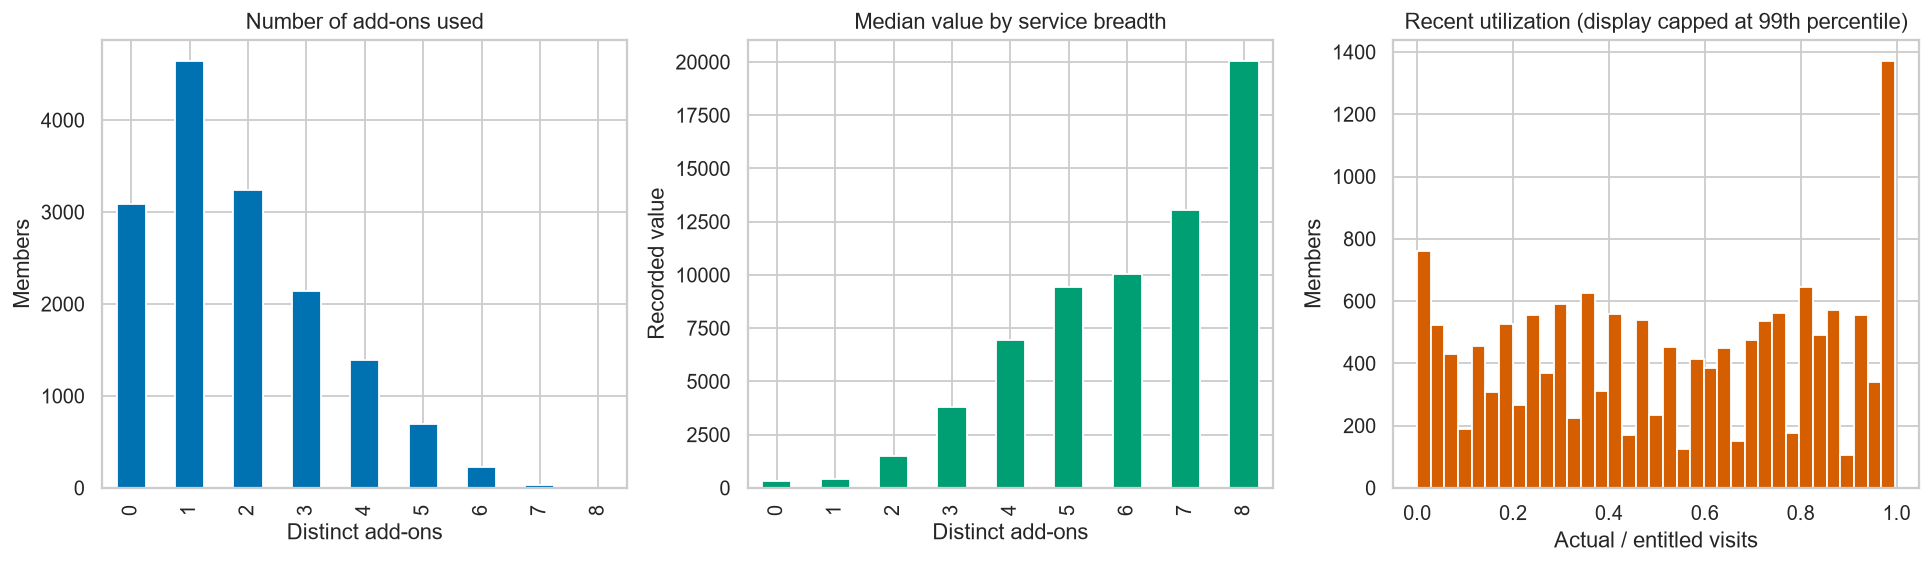

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
view["service_breadth"].value_counts().sort_index().plot.bar(
    ax=axes[0], color="#0072B2")
axes[0].set(title="Number of add-ons used", xlabel="Distinct add-ons", ylabel="Members")
median_by_breadth = view.groupby("service_breadth")["lifetime_value"].median()
median_by_breadth.plot.bar(ax=axes[1], color="#009E73")
axes[1].set(title="Median value by service breadth", xlabel="Distinct add-ons", ylabel="Recorded value")
util_plot = view["recent_utilization"].clip(upper=view["recent_utilization"].quantile(.99))
util_plot.hist(bins=35, ax=axes[2], color="#D55E00")
axes[2].set(title="Recent utilization (display capped at 99th percentile)",
            xlabel="Actual / entitled visits", ylabel="Members")
fig.tight_layout()
plt.show()

,members,median_utilization,median_service_breadth
tier,,,
Hot desk,5212,0.46,1.0
Flex,5449,0.57,1.0
Dedicated desk,1549,0.74,3.0
Full time,2471,0.33,2.0
Private office,664,0.15,3.0


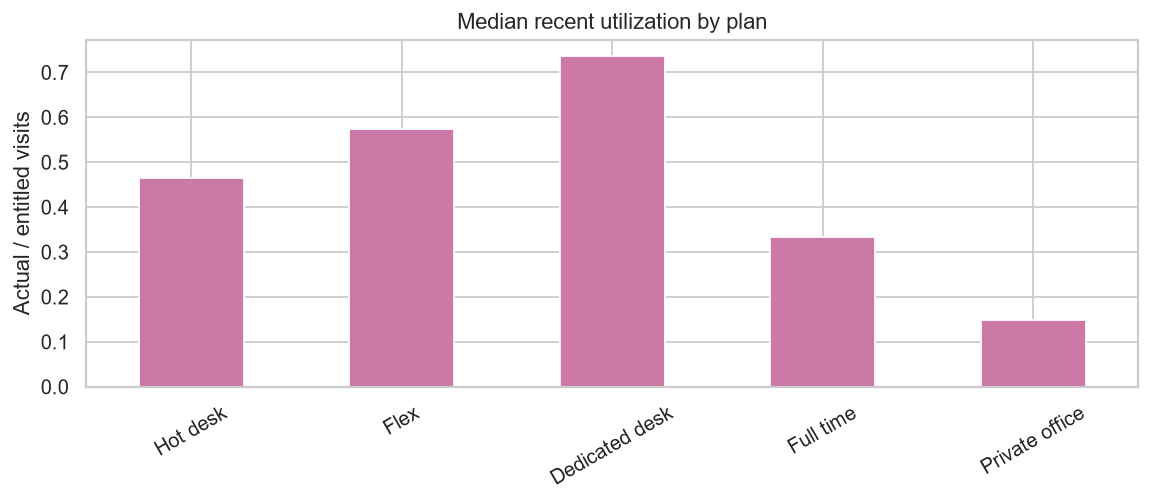

In [17]:
util_profile = view.groupby("tier").agg(
    members=("recent_utilization", "size"),
    median_utilization=("recent_utilization", "median"),
    median_service_breadth=("service_breadth", "median"),
).reindex(tier_order)
display(util_profile.round(2))
fig, ax = plt.subplots(figsize=(9, 4))
util_profile["median_utilization"].plot.bar(ax=ax, color="#CC79A7")
ax.set(title="Median recent utilization by plan", xlabel="", ylabel="Actual / entitled visits")
ax.tick_params(axis="x", rotation=30)
fig.tight_layout()
plt.show()

The service-breadth/value gradient is useful for a segmentation hypothesis but may reflect plan price, member tenure, and account size. Recent utilization compares usage with entitlement, so it can distinguish high- and low-engagement members within a tier. The low private-office ratio is worth investigating; a team plan may make per-member entitlements and swipes difficult to compare.

## 7. Associations and correlation

**Correlation** measures how two variables move together. Pearson measures a linear relationship; Spearman measures whether values tend to rise or fall together in rank order. Both range from −1 to +1. Near zero means little *measured* relationship of that type, not necessarily independence. Correlation does not establish causation. We use Spearman because several variables are skewed and contain extreme values. Pairwise calculations can use different numbers of complete rows.

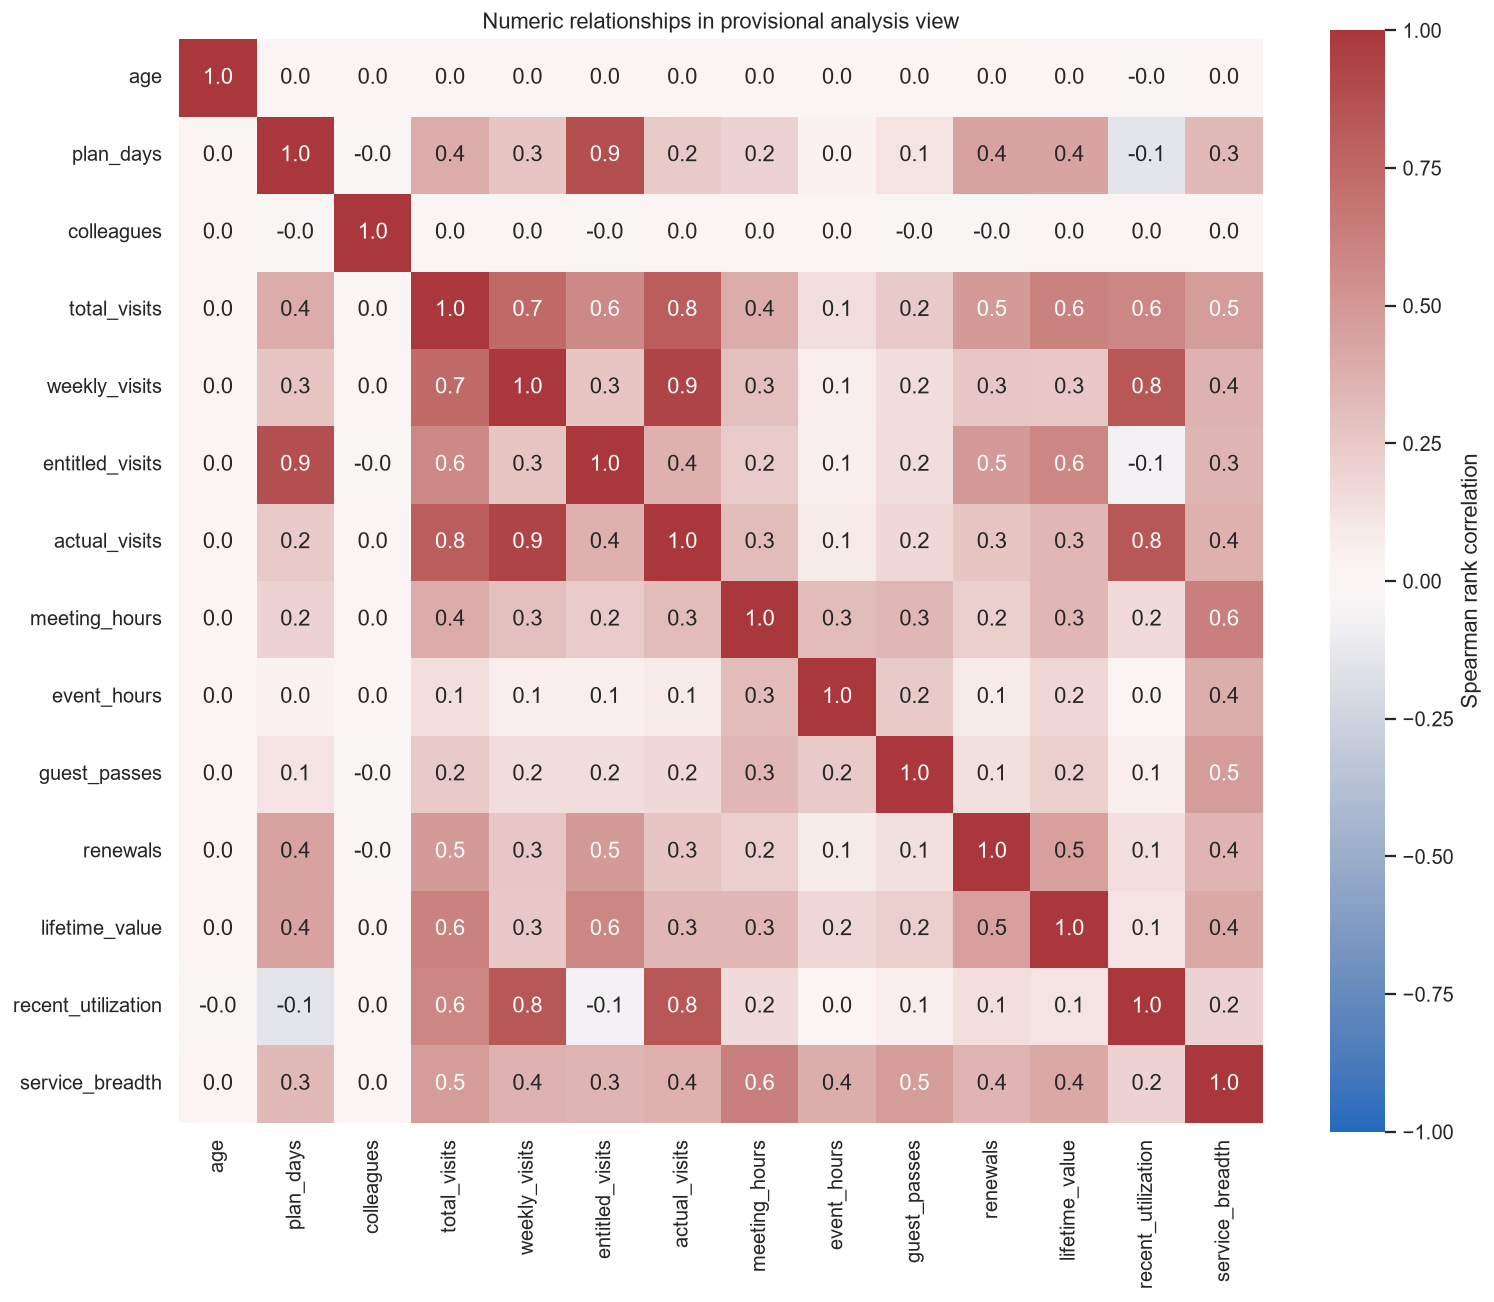

,feature_a,feature_b,spearman_rho,absolute_rho
62,weekly_visits,actual_visits,0.933,0.933
19,plan_days,entitled_visits,0.880,0.880
96,actual_visits,recent_utilization,0.843,0.843
68,weekly_visits,recent_utilization,0.840,0.840
48,total_visits,actual_visits,0.811,0.811
46,total_visits,weekly_visits,0.735,0.735
111,meeting_hours,service_breadth,0.631,0.631
53,total_visits,lifetime_value,0.611,0.611
54,total_visits,recent_utilization,0.591,0.591
81,entitled_visits,lifetime_value,0.590,0.590


In [18]:
corr_columns = ["age", "plan_days", "colleagues", "total_visits",
                "weekly_visits", "entitled_visits", "actual_visits",
                "meeting_hours", "event_hours", "guest_passes", "renewals",
                "lifetime_value", "recent_utilization", "service_breadth"]
corr = view[corr_columns].corr(method="spearman", min_periods=100)
fig, ax = plt.subplots(figsize=(12, 10))
sns.heatmap(corr, vmin=-1, vmax=1, center=0, cmap="vlag",
            annot=True, fmt=".1f", square=True, ax=ax,
            cbar_kws={"label": "Spearman rank correlation"})
ax.set_title("Numeric relationships in provisional analysis view")
fig.tight_layout()
plt.show()

pairs = (corr.where(np.triu(np.ones(corr.shape), 1).astype(bool))
         .stack().rename("spearman_rho").reset_index())
pairs.columns = ["feature_a", "feature_b", "spearman_rho"]
pairs["absolute_rho"] = pairs["spearman_rho"].abs()
display(pairs.nlargest(12, "absolute_rho").round(3))

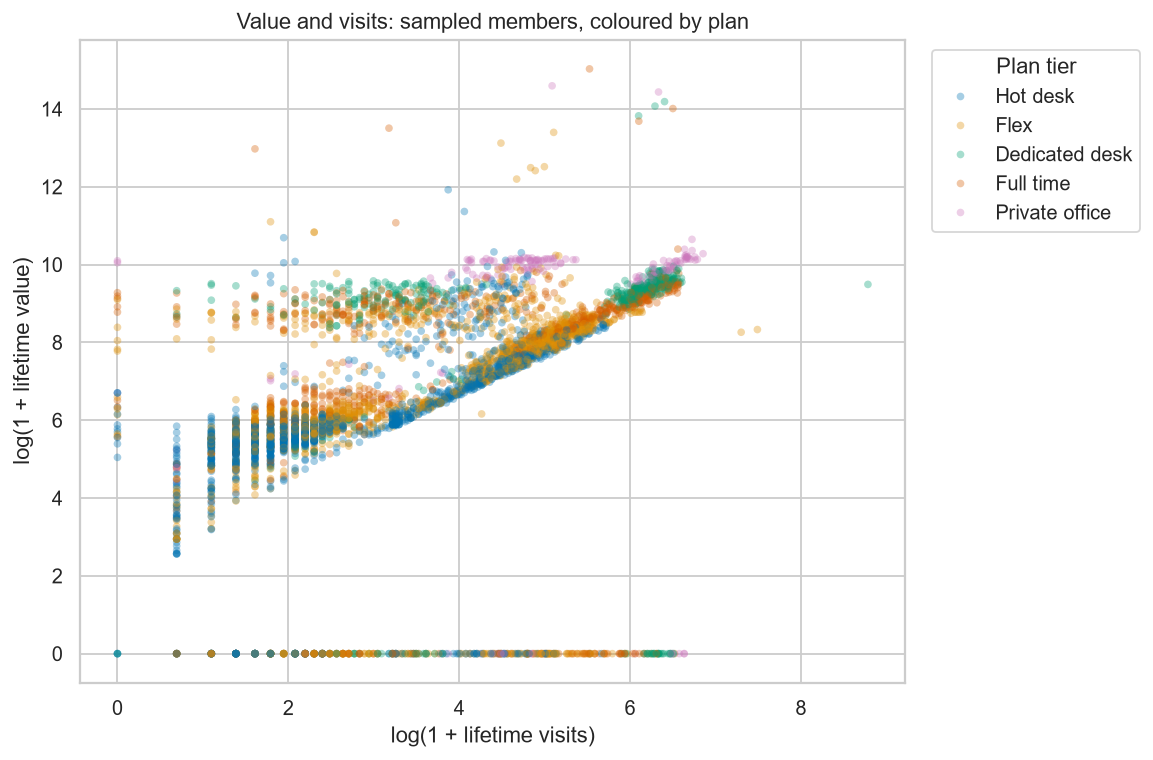

,correlation
Spearman visits–value,0.611
Pearson visits–value,0.140


In [19]:
scatter = view[["total_visits", "lifetime_value", "tier"]].dropna()
scatter = scatter.sample(n=min(4500, len(scatter)), random_state=42)
fig, ax = plt.subplots(figsize=(9, 6))
sns.scatterplot(data=scatter, x=np.log1p(scatter["total_visits"]),
                y=np.log1p(scatter["lifetime_value"]), hue="tier",
                hue_order=tier_order, alpha=.35, s=18, linewidth=0, ax=ax)
ax.set(xlabel="log(1 + lifetime visits)", ylabel="log(1 + lifetime value)",
       title="Value and visits: sampled members, coloured by plan")
ax.legend(title="Plan tier", bbox_to_anchor=(1.02, 1), loc="upper left")
fig.tight_layout()
plt.show()

association = pd.Series({
    "Spearman visits–value": view["total_visits"].corr(view["lifetime_value"], method="spearman"),
    "Pearson visits–value": view["total_visits"].corr(view["lifetime_value"], method="pearson"),
})
display(association.to_frame("correlation").round(3))

The heatmap highlights potential redundancy. Weekly visits and recent actual visits largely describe attendance; plan days and entitlement also overlap. Feeding every strongly correlated measure into distance-based clustering would over-weight a single behavior. The scatter plot shows that visit count and value rise together overall but with substantial spread and plan differences. The Pearson/Spearman gap is another sign that raw outliers distort a simple linear summary.

## 8. Findings to review with the group

1. **Value perspective:** Median lifetime value differs sharply by tier, from about 321 for hot desk to 20,000 for private office. This may reflect plan price and membership duration as well as behavior.
2. **Behavior perspective:** Dedicated-desk members have a higher median weekly visit rate than several other tiers, while private-office members have high recorded value but low median recent utilization. Investigate account-level recording before interpreting the latter.
3. **Engagement breadth:** Median recorded value increases with the number of add-ons used, but this is an association, not evidence that add-ons cause spending.
4. **Skew and outliers:** The top 1% of nonnegative parsed lifetime values account for about 46.3% of the total. Raw-value clustering would be very sensitive to these members.
5. **Quality risks:** The data contains exact duplicates, mixed category and date formats, possible placeholders, negative quantities, and contradictory activity flags. They could create artificial clusters if treated as ordinary measurements.

**Provisional segment hypotheses, not cluster results:** low-use basic access; regular desk users; high-value private-office accounts; service-intensive members; and possibly low-engagement members. These groups can overlap. EDA does not justify a final number of clusters; the clustering phase must test stability and business usefulness.

## 9. Preparation decisions for the next CRISP-DM phase

| Decision to make | Why it matters | Evidence or validation needed |
|---|---|---|
| Confirm member and account grain | Team plans may record value, entitlement, and visits at different levels | Source-system definitions and examples |
| Standardize category labels | Case, spaces, abbreviations, and aliases inflate categories | Approved mapping for tier, gender, industry, country |
| Define date placeholders and extraction date | Tenure and recency may otherwise be wrong | Meaning of 1970 end date and 999-day recency; date reference |
| Resolve invalid/contradictory values | Negative counts and conflicting flags can distort distances | Billing reversals, corrections, extra visits, event logs |
| Handle missingness by field | Blank may mean unknown, not used, or not recorded | Collection rules; group-rate comparisons; sensitivity checks |
| Limit value outlier influence | A few records dominate raw monetary scale | Investigate extreme accounts; compare robust/log scaling |
| Choose features by perspective | Correlated measures double-count behavior | Value vs behavior feature sets; stability across choices |

**Next modeling phase:** prepare separate value and behavior views, compare at least two clustering methods for each, then evaluate cluster stability, size, interpretability, and business actionability. Keep a record of every preprocessing decision and run sensitivity analyses for uncertain rules. No imputation, trimming, or cluster assignment is performed in this EDA notebook.

## Review and attribution

This notebook was drafted with AI assistance at the user's request. The assignment permits AI assistance but requires disclosure and expects the students' own analytical judgment. The group should verify every definition, rerun all cells, challenge the hypotheses, write its own interpretations, and disclose the assistance in the required annex. Rename the final submitted notebook to the assigned `GroupXX_EDA_Code.ipynb` format once the group number is known.